	Predicting Stock Market Prices	Perform exhaustive hyperparameter optimization for the Decision Tree Regressor using GridSearchCV, evaluating a wide range of parameters (max_depth, min_samples_split, etc.) through cross-validation to enhance model generalization and prevent overfitting.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df = pd.read_csv('TSLA_cleaned_data.csv')
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').drop_duplicates(subset=['Date'], keep='last').reset_index(drop=True)

# Leakage-free lag & technical features (anchored at t-1)
s_close = df['Close'].shift(1)
df['Close_Lag_1'] = df['Close'].shift(1)
df['Close_Lag_2'] = df['Close'].shift(2)
df['Close_Lag_5'] = df['Close'].shift(5)
df['EMA_7'] = s_close.ewm(span=7, adjust=False).mean()
df['SMA_10'] = s_close.rolling(10).mean()
df['SMA_20'] = s_close.rolling(20).mean()
df['Log_Return_Lag1'] = np.log(df['Close'].shift(1) / df['Close'].shift(2))
df['Volume_Lag1'] = df['Volume'].shift(1)

delta = s_close.diff()
avg_gain = delta.clip(lower=0).ewm(alpha=1/14, min_periods=14, adjust=False).mean()
avg_loss = (-delta.clip(upper=0)).ewm(alpha=1/14, min_periods=14, adjust=False).mean()
df['RSI_14'] = 100 - (100 / (1 + (avg_gain / avg_loss)))

df['MACD'] = s_close.ewm(span=12, adjust=False).mean() - s_close.ewm(span=26, adjust=False).mean()
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

bb_mid = s_close.rolling(20).mean()
bb_std = s_close.rolling(20).std()
df['BB_Width'] = (4 * bb_std) / bb_mid
df['BB_PctB'] = (s_close - (bb_mid - 2 * bb_std)) / (4 * bb_std)

df_model = df.dropna().reset_index(drop=True)
features = [
    'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_5', 'EMA_7', 'SMA_10', 'SMA_20',
    'Log_Return_Lag1', 'RSI_14', 'MACD', 'MACD_Signal', 'MACD_Hist',
    'BB_Width', 'BB_PctB', 'Volume_Lag1'
]

split = int(len(df_model) * 0.80)
X_train, y_train = df_model.iloc[:split][features], df_model.iloc[:split]['Close']
X_test, y_test = df_model.iloc[split:][features], df_model.iloc[split:]['Close']
test_dates = df_model.iloc[split:]['Date']

In [5]:
param_grid = {
    'criterion': ['squared_error', 'absolute_error'],
    'max_depth': [2, 3, 4, 5, None],
    'min_samples_split': [2, 5, 8],
    'min_samples_leaf': [1, 2, 4],
    'ccp_alpha': [0.0, 0.05]
}

tscv = TimeSeriesSplit(n_splits=4)
grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_squared_error',
    n_jobs=1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)
best_dt = grid_search.best_estimator_

print("Total Combinations Evaluated:", len(grid_search.cv_results_['params']))
print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best CV RMSE: ${np.sqrt(-grid_search.best_score_):.4f}")

Total Combinations Evaluated: 180
Best Hyperparameters: {'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best CV RMSE: $6.3805


In [6]:
# Top 5 GridSearchCV parameter combinations
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results['CV_RMSE'] = np.sqrt(-cv_results['mean_test_score'])
cv_results['Train_CV_RMSE'] = np.sqrt(-cv_results['mean_train_score'])
print("--- Top 5 Hyperparameter Combinations (by TimeSeriesSplit CV RMSE) ---")
print(cv_results.sort_values('CV_RMSE')[['params', 'Train_CV_RMSE', 'CV_RMSE']].head(5).to_string(index=False))

# Compare Base (Overfit) vs. Exhaustively Tuned Model on Holdout Test Set
base_dt = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)

summary = []
for name, model in [('Default Unconstrained DT', base_dt), ('Exhaustively Tuned DT', best_dt)]:
    tr_p, te_p = model.predict(X_train), model.predict(X_test)
    summary.append({
        'Model': name,
        'Depth': model.get_depth(),
        'Leaves': model.get_n_leaves(),
        'Train_RMSE ($)': round(np.sqrt(mean_squared_error(y_train, tr_p)), 4),
        'Test_RMSE ($)': round(np.sqrt(mean_squared_error(y_test, te_p)), 4),
        'Test_MAE ($)': round(mean_absolute_error(y_test, te_p), 4),
        'Test_R2': round(r2_score(y_test, te_p), 4)
    })

print("\n--- Overfitting Reduction & Out-of-Sample Generalization ---")
print(pd.DataFrame(summary).to_string(index=False))

--- Top 5 Hyperparameter Combinations (by TimeSeriesSplit CV RMSE) ---
                                                                                                             params  Train_CV_RMSE  CV_RMSE
    {'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 5}       2.076231 6.380525
   {'ccp_alpha': 0.05, 'criterion': 'squared_error', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 5}       2.076231 6.380525
   {'ccp_alpha': 0.0, 'criterion': 'absolute_error', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5}       1.462211 6.623310
  {'ccp_alpha': 0.05, 'criterion': 'absolute_error', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5}       1.468064 6.623310
{'ccp_alpha': 0.05, 'criterion': 'squared_error', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5}       1.307021 6.629801

--- Overfitting Reduction & Out-of-Sample Generalization ---
                   Model  D

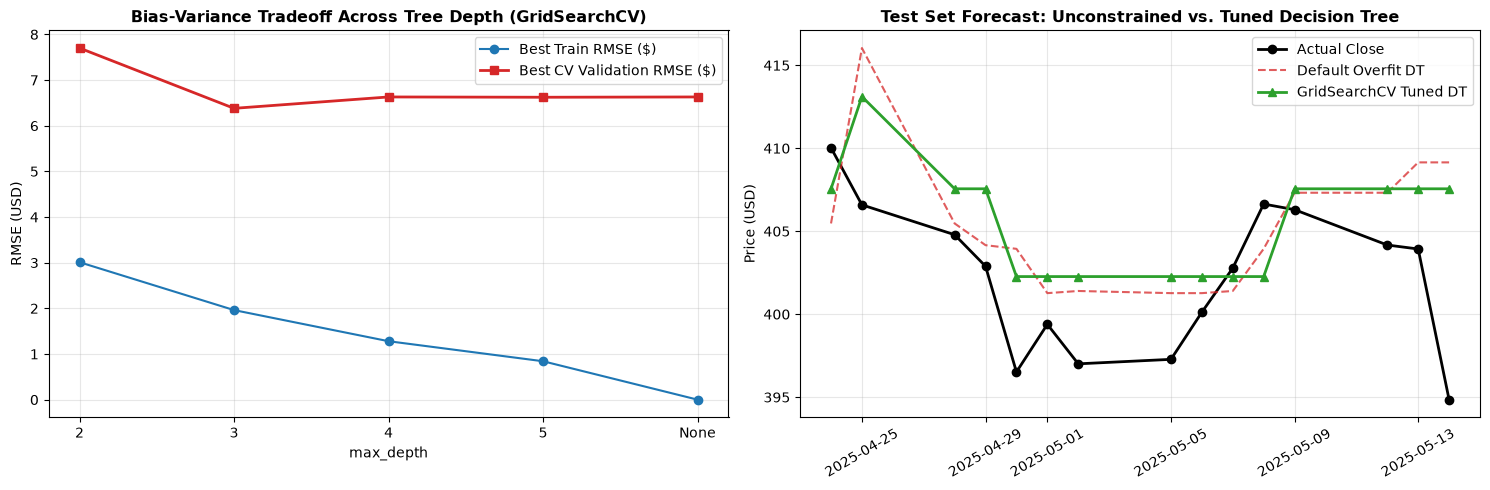

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Validation Curve: Train vs. CV RMSE by max_depth
depth_perf = cv_results.groupby(cv_results['param_max_depth'].fillna('None').astype(str))[['Train_CV_RMSE', 'CV_RMSE']].min()
depth_order = ['2', '3', '4', '5', '6', '8', 'None']
depth_perf = depth_perf.reindex([d for d in depth_order if d in depth_perf.index])

axes[0].plot(depth_perf.index, depth_perf['Train_CV_RMSE'], marker='o', label='Best Train RMSE ($)', color='#1f77b4')
axes[0].plot(depth_perf.index, depth_perf['CV_RMSE'], marker='s', linewidth=2, label='Best CV Validation RMSE ($)', color='#d62728')
axes[0].set_title('Bias-Variance Tradeoff Across Tree Depth (GridSearchCV)', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('max_depth')
axes[0].set_ylabel('RMSE (USD)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 2. Test Predictions: Default Overfit Tree vs. GridSearchCV Tuned Tree
axes[1].plot(test_dates, y_test, color='black', marker='o', linewidth=2, label='Actual Close')
axes[1].plot(test_dates, base_dt.predict(X_test), color='#d62728', linestyle='--', alpha=0.75, label='Default Overfit DT')
axes[1].plot(test_dates, best_dt.predict(X_test), color='#2ca02c', marker='^', linewidth=2, label='GridSearchCV Tuned DT')
axes[1].set_title('Test Set Forecast: Unconstrained vs. Tuned Decision Tree', fontsize=11.5, fontweight='bold')
axes[1].set_ylabel('Price (USD)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()